# Chapter 11: When Multiplication Shrinks

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** see why multiplying by a factor below 1 makes things smaller, why the bottoms multiply when you take a share of a share, and how dividing by a small group counts how many groups fit, even when the count is a fraction.

A note before we start: the code cells are optional reading. You do not need to run them or understand them. The results and the pictures are shown right below each one, so you can read straight through like a book.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from matplotlib.patches import Rectangle

TEAL, GOLD, TERRA, NAVY, INK, GREY, LIGHT = "#1f7a80", "#c9a227", "#c4552d", "#1f3a5f", "#222222", "#777777", "#dddddd"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})

def frac(x):
    """Write a Fraction the plain way: 3/4, or 2 for a whole number."""
    x = Fraction(x)
    return str(x.numerator) if x.denominator == 1 else f"{x.numerator}/{x.denominator}"

def mixed(x):
    """Write a Fraction as a mixed number: 11/4 becomes 2 3/4."""
    x = Fraction(x)
    whole, rem = divmod(x.numerator, x.denominator)
    if rem == 0:
        return str(whole)
    if whole == 0:
        return f"{rem}/{x.denominator}"
    return f"{whole} {rem}/{x.denominator}"

def bare(ax):
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)

## 1. The factor decides grow or shrink

**Question in plain words:** When does multiplying a positive length make it shorter?

$$8 \times \tfrac12 = 4$$

**What the symbols mean:** 8 is the original length in units of a scale drawing. The scale factor $a/b$ means: cut the length into $b$ equal shares and take $a$ of them. Here the factor is $1/2$.

In [2]:
start = 8
f = Fraction(1, 2)
share = Fraction(start, f.denominator)
result = start * f
print(f"factor compared with 1: {frac(f)} is between 0 and 1")
print(f"cut {start} into {f.denominator} equal shares of {start} / {f.denominator} = {frac(share)}")
print(f"take {f.numerator}: {f.numerator} x {frac(share)} = {frac(result)}")
print(f"new length = {start} x {frac(f)} = {mixed(result)}")
print(f"change: shorter by {start} - {mixed(result)} = {mixed(start - result)}")

print()
print("Other menu values:")
for name, g in [("1/2", Fraction(1,2)), ("3/4", Fraction(3,4)), ("1", Fraction(1)), ("3/2", Fraction(3,2))]:
    r = start * g
    kind = "shrinks" if g < 1 else ("stays the same" if g == 1 else "grows")
    print(f"  8 x {name} = {mixed(r)}  ({kind})")
print()
print("Check from the chapter's practice: 8 x 5/4: 8 / 4 = 2, then 5 x 2 = 10, bigger than 8 because 5/4 > 1")

factor compared with 1: 1/2 is between 0 and 1
cut 8 into 2 equal shares of 8 / 2 = 4
take 1: 1 x 4 = 4
new length = 8 x 1/2 = 4
change: shorter by 8 - 4 = 4

Other menu values:
  8 x 1/2 = 4  (shrinks)
  8 x 3/4 = 6  (shrinks)
  8 x 1 = 8  (stays the same)
  8 x 3/2 = 12  (grows)

Check from the chapter's practice: 8 x 5/4: 8 / 4 = 2, then 5 x 2 = 10, bigger than 8 because 5/4 > 1


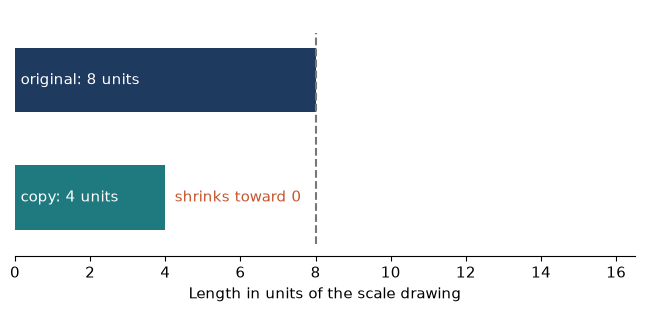

In [3]:
def scale(f):
    f = Fraction(f)
    result = 8 * f
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.barh([1.4], [8], height=0.55, color=NAVY)
    ax.barh([0.4], [float(result)], height=0.55, color=TEAL)
    ax.text(0.15, 1.4, "original: 8 units", va="center", color="white")
    ax.text(0.15, 0.4, f"copy: {mixed(result)} units", va="center", color="white")
    word = "shrinks toward 0" if f < 1 else ("stays the same" if f == 1 else "grows away from 0")
    ax.text(float(result)+0.25, 0.4, word, va="center", color=TERRA)
    ax.plot([8, 8], [0, 1.8], color=GREY, ls="dashed")
    ax.set_xlim(0, 16.5); ax.set_ylim(-0.1, 2.0)
    ax.set_xlabel("Length in units of the scale drawing"); bare(ax)
    plt.show()

scale(Fraction(1, 2))

**What this shows:** The top bar stays at 8. The lower bar is the scaled copy. A factor below 1 keeps fewer shares than make up the whole, so the result is smaller. A factor above 1 keeps more, so it grows. Before multiplying, compare the factor with 1 and you know whether the answer should be bigger or smaller.

**Where it stops working:** We assumed a positive starting length and a positive factor. With negative numbers, "bigger" and "smaller" need more care, and a factor of 0 sends any length to 0.

## 2. A share of a share is an overlap

**Question in plain words:** What is three fourths of two thirds, and why do the bottoms multiply?

$$\left(\tfrac34\right) \times \left(\tfrac23\right) = \frac{3 \times 2}{4 \times 3} = \frac{6}{12} = \frac12 \qquad\qquad 6 \times \tfrac1{12} = \tfrac6{12} = \tfrac12$$

**What the symbols mean:** Columns cut the whole into thirds; rows cut it into fourths. Together they make 12 equal cells, each $1/12$. The column choice is the second fraction. The row choice, the first fraction, takes a share of that. The overlap counts the cells chosen both ways.

In [4]:
rows, cols = 3, 2
selected = cols * 4
overlap = rows * cols
prod = Fraction(rows, 4) * Fraction(cols, 3)
print(f"cells in the chosen columns: {cols} x 4 = {selected}")
print(f"keep {rows} of every 4 rows: ({selected} / 4) x {rows} = {overlap} overlap cells")
print(f"product: ({rows} x {cols})/(4 x 3) = {overlap}/12 = {frac(prod)}")
print(f"compare with {cols}/3: {frac(prod)} is smaller, because {rows}/4 is less than 1")

print()
print("Other menu values (rows of 4, columns of 3):")
for r in [1, 2, 3, 4]:
    for c in [1, 2]:
        p = Fraction(r, 4) * Fraction(c, 3)
        print(f"  ({r}/4) x ({c}/3) = ({r} x {c})/(4 x 3) = {r*c}/12 = {frac(p)}")
print()
print("Chapter practice: (1/4) x (2/3) = (1 x 2)/(4 x 3) = 2/12 =", frac(Fraction(2,12)))

cells in the chosen columns: 2 x 4 = 8
keep 3 of every 4 rows: (8 / 4) x 3 = 6 overlap cells
product: (3 x 2)/(4 x 3) = 6/12 = 1/2
compare with 2/3: 1/2 is smaller, because 3/4 is less than 1

Other menu values (rows of 4, columns of 3):
  (1/4) x (1/3) = (1 x 1)/(4 x 3) = 1/12 = 1/12
  (1/4) x (2/3) = (1 x 2)/(4 x 3) = 2/12 = 1/6
  (2/4) x (1/3) = (2 x 1)/(4 x 3) = 2/12 = 1/6
  (2/4) x (2/3) = (2 x 2)/(4 x 3) = 4/12 = 1/3
  (3/4) x (1/3) = (3 x 1)/(4 x 3) = 3/12 = 1/4
  (3/4) x (2/3) = (3 x 2)/(4 x 3) = 6/12 = 1/2
  (4/4) x (1/3) = (4 x 1)/(4 x 3) = 4/12 = 1/3
  (4/4) x (2/3) = (4 x 2)/(4 x 3) = 8/12 = 2/3

Chapter practice: (1/4) x (2/3) = (1 x 2)/(4 x 3) = 2/12 = 1/6


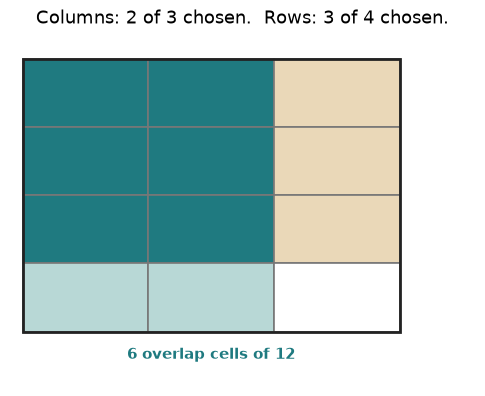

In [5]:
def overlap_grid(rows=3, cols=2):
    fig, ax = plt.subplots(figsize=(6, 4.6))
    for r in range(4):
        for c in range(3):
            ir, ic = r < rows, c < cols
            color = TEAL if (ir and ic) else ("#b8d8d6" if ic else ("#ead8b8" if ir else "white"))
            ax.add_patch(Rectangle((c, 3-r), 1, 1, facecolor=color, edgecolor=GREY, lw=1.2))
    ax.add_patch(Rectangle((0, 0), 3, 4, fill=False, edgecolor=INK, lw=2))
    ax.text(1.5, -0.4, f"{rows*cols} overlap cells of 12", ha="center", fontweight="bold", color=TEAL)
    ax.set_xlim(-0.1, 3.6); ax.set_ylim(-0.8, 4.4); ax.axis("off")
    ax.set_title(f"Columns: {cols} of 3 chosen.  Rows: {rows} of 4 chosen.")
    plt.show()

overlap_grid(3, 2)

**What this shows:** The dark cells belong to both choices, so their count (6) is the numerator and the 12 cells are the denominator. That is why the bottoms multiply: $4 \times 3 = 12$ equal cells.

**Where it stops working:** All 12 cells must be equal, and both fractions must be shares of the same whole. If the rows were unequal, counting cells would not give twelfths.

## 3. Count the groups that fit

**Question in plain words:** How many groups of one eighth fit inside three fourths?

$$\left(\tfrac34\right) \div \left(\tfrac18\right) = 6 \qquad\qquad 6 \times \tfrac18 = \tfrac68 = \tfrac34$$

**What the symbols mean:** $3/4$ is the amount available. $1/8$ is the size of one group. The answer counts groups, not a share of the whole.

In [6]:
amount, group = Fraction(3, 4), 8
count = amount / Fraction(1, group)
print(f"rename in the group's unit: {frac(amount)} = (3 x 2)/(4 x 2) = {int(count)}/{group}")
print(f"that is {int(count)} groups of 1/{group}")
print(f"so ({frac(amount)}) / (1/{group}) = {int(count)}")
print(f"reciprocal route: {frac(amount)} x {group} = {int(count)}")
print(f"check: {int(count)} x 1/{group} = {int(count)}/{group} = {frac(amount)}")

print()
print("Other menu values:")
for av in [Fraction(3,4), Fraction(1,2)]:
    for g in [4, 8, 16]:
        print(f"  ({frac(av)}) / (1/{g}) = {frac(av)} x {g} = {frac(av*g)}")

rename in the group's unit: 3/4 = (3 x 2)/(4 x 2) = 6/8
that is 6 groups of 1/8
so (3/4) / (1/8) = 6
reciprocal route: 3/4 x 8 = 6
check: 6 x 1/8 = 6/8 = 3/4

Other menu values:
  (3/4) / (1/4) = 3/4 x 4 = 3
  (3/4) / (1/8) = 3/4 x 8 = 6
  (3/4) / (1/16) = 3/4 x 16 = 12
  (1/2) / (1/4) = 1/2 x 4 = 2
  (1/2) / (1/8) = 1/2 x 8 = 4
  (1/2) / (1/16) = 1/2 x 16 = 8


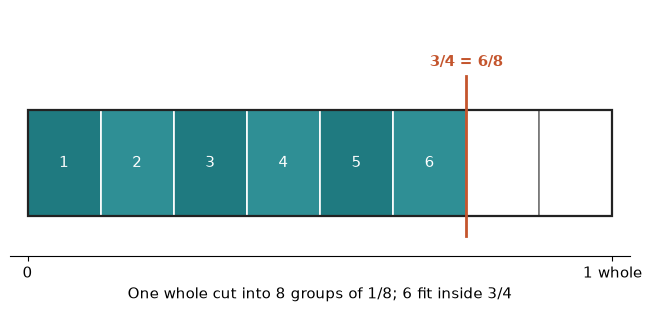

In [7]:
def fit(group=8, amount=Fraction(3, 4)):
    count = int(amount * group)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    for k in range(group):
        inside = k < count
        ax.add_patch(Rectangle((k/group, 0.3), 1/group, 0.8, facecolor=(TEAL if k % 2 == 0 else "#2f8f95") if inside else "white",
                               edgecolor="white" if inside else GREY, lw=1.2))
        if inside and group <= 8:
            ax.text((k+0.5)/group, 0.7, str(k+1), ha="center", va="center", color="white")
    ax.add_patch(Rectangle((0, 0.3), 1, 0.8, fill=False, edgecolor=INK, lw=1.6))
    ax.plot([float(amount)]*2, [0.15, 1.35], color=TERRA, lw=2)
    ax.text(float(amount), 1.4, f"{frac(amount)} = {count}/{group}", ha="center", va="bottom", color=TERRA, fontweight="bold")
    ax.set_xlim(-0.03, 1.03); ax.set_ylim(0, 1.85)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["0", "1 whole"])
    ax.set_xlabel(f"One whole cut into {group} groups of 1/{group}; {count} fit inside {frac(amount)}")
    bare(ax); plt.show()

fit(8, Fraction(3, 4))

**What this shows:** Rename the available amount in the group's unit, then count. The red line marks the amount, and every shaded piece to its left is one group. The count (6) is bigger than $3/4$ because each group is small.

**Where it stops working:** Each group must have the same size, and the group size cannot be zero. Here every group fits a whole number of times; the next demonstration shows a leftover.

## 4. A group count can contain a fraction

**Question in plain words:** If five sixths are available and a group needs two thirds, how many groups are there?

$$\frac56\div\frac23=\frac56\div\frac46=5\div4=\frac54$$

**What the symbols mean:** $5/6$ is the amount available, counted in sixth-sized pieces. $2/3 = 4/6$ is one group. The answer counts groups, so a leftover is measured against a group.

In [8]:
available, group = 5, 4
avail = Fraction(available, 6)
q = Fraction(available, group)
full, left = divmod(available, group)
print(f"available: {frac(avail)}, which is {available}/6")
print(f"one group: 2/3 = (2 x 2)/(3 x 2) = {group}/6")
print(f"groups: ({available}/6) / ({group}/6) = {available} / {group} = {frac(q)} = {mixed(q)}")
print(f"{full} complete group fits and {left} piece is left; the leftover is {left}/{group} of a group, not {left}/6")
print(f"check: {frac(q)} x 2/3 = {frac(q * Fraction(group, 6))} = {available}/6")

print()
print("Other menu values:")
for av in [2, 4, 5]:
    for gp, name in [(4, "2/3"), (3, "1/2")]:
        qq = Fraction(av, gp)
        print(f"  ({av}/6) / ({name}) = ({av}/6) / ({gp}/6) = {av} / {gp} = {frac(qq)}" + (f" = {mixed(qq)}" if qq > 1 and qq.denominator > 1 else ""))
print()
print("Chapter practice: groups of 3/4 = 6/8 in 3/8: 3 / 6 =", frac(Fraction(3,6)), "group; check 1/2 x 3/4 = 3/8")

available: 5/6, which is 5/6
one group: 2/3 = (2 x 2)/(3 x 2) = 4/6
groups: (5/6) / (4/6) = 5 / 4 = 5/4 = 1 1/4
1 complete group fits and 1 piece is left; the leftover is 1/4 of a group, not 1/6
check: 5/4 x 2/3 = 5/6 = 5/6

Other menu values:
  (2/6) / (2/3) = (2/6) / (4/6) = 2 / 4 = 1/2
  (2/6) / (1/2) = (2/6) / (3/6) = 2 / 3 = 2/3
  (4/6) / (2/3) = (4/6) / (4/6) = 4 / 4 = 1
  (4/6) / (1/2) = (4/6) / (3/6) = 4 / 3 = 4/3 = 1 1/3
  (5/6) / (2/3) = (5/6) / (4/6) = 5 / 4 = 5/4 = 1 1/4
  (5/6) / (1/2) = (5/6) / (3/6) = 5 / 3 = 5/3 = 1 2/3

Chapter practice: groups of 3/4 = 6/8 in 3/8: 3 / 6 = 1/2 group; check 1/2 x 3/4 = 3/8


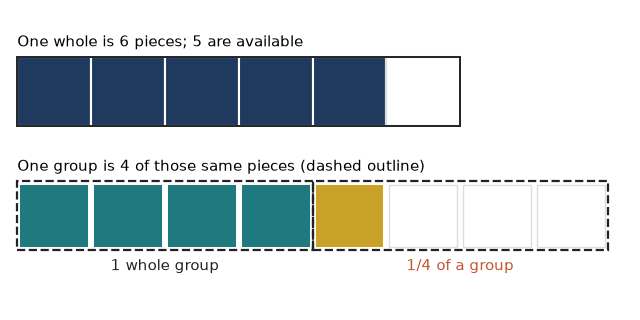

In [9]:
def groups(available=5, group=4):
    full, left = divmod(available, group)
    fig, ax = plt.subplots(figsize=(8, 3.9))
    for k in range(6):
        ax.add_patch(Rectangle((k, 2.0), 1, 0.8, facecolor=NAVY if k < available else "white",
                               edgecolor="white" if k < available else LIGHT, lw=1.5))
    ax.add_patch(Rectangle((0, 2.0), 6, 0.8, fill=False, edgecolor=INK, lw=1.4))
    ax.text(0, 2.88, f"One whole is 6 pieces; {available} are available", va="bottom")
    for g in range(full + (1 if left else 0)):
        x0 = g * group
        ax.add_patch(Rectangle((x0, 0.55), group, 0.8, fill=False, edgecolor=INK, ls="dashed", lw=1.6, zorder=4))
        for k in range(group):
            p = x0 + k
            color = (TEAL if g < full else GOLD) if p < available else "white"
            ax.add_patch(Rectangle((p+0.04, 0.59), 0.92, 0.72, facecolor=color,
                                   edgecolor="none" if p < available else LIGHT))
        text = "1 whole group" if g < full else f"{left}/{group} of a group"
        ax.text(x0 + group/2, 0.45, text, ha="center", va="top", color=INK if g < full else TERRA)
    ax.text(0, 1.43, f"One group is {group} of those same pieces (dashed outline)", va="bottom")
    ax.set_xlim(-0.1, 8.3); ax.set_ylim(-0.15, 3.35); ax.set_xticks([]); ax.spines["bottom"].set_visible(False)
    bare(ax); plt.show()

groups(5, 4)

**What this shows:** Each sixth-sized piece is the same size throughout. The dashed outlines mark groups of 4 pieces. One full group fits, and the leftover piece fills 1 of the 4 pieces a group needs, so it is $1/4$ of a group. Together: $5/4 = 1\frac14$ groups.

**Where it stops working:** The pieces must be equal and the amount must be splittable, like length or volume. If only full containers count, report 1 group and 1 piece left over instead of $5/4$.

## Practice

**1.** What is $8 \times 5/4$, and is it bigger or smaller than 8?

<details><summary>Show answer</summary>

$8 \div 4 = 2$, and $5 \times 2 = 10$. Since $5/4$ is greater than 1, 10 is bigger than 8.
</details>

**2.** Using the same grid, what is $(1/4) \times (2/3)$?

<details><summary>Show answer</summary>

$(1 \times 2)/(4 \times 3) = 2/12 = 1/6$: one chosen row crosses two chosen columns in 2 cells out of 12.
</details>

**3.** How many groups of $1/8$ fit inside $1/2$, and how do you check it?

<details><summary>Show answer</summary>

$1/2 = (1 \times 4)/(2 \times 4) = 4/8$, so 4 groups fit. Check: $4 \times 1/8 = 4/8 = 1/2$.
</details>

**4.** Using groups of $3/4 = 6/8$, how many groups are in $3/8$?

<details><summary>Show answer</summary>

There are 3 pieces out of the 6 a group needs: $3 \div 6 = 1/2$ group. Check: $1/2 \times 3/4 = 3/8$.
</details>